# 05 - Language identification (Hindi vs Marathi) and the complete system

Both languages use the Devanagari script, so we cannot detect the language from the script. We identify it from the
**recognised text**: TF-IDF over character 1-4 grams + logistic regression, trained on training transcripts only
(plus noisy copies that imitate recognition errors, and short word windows).

Evaluation:

* A. validation and test pages using the **true** transcripts (upper bound)
* B. test pages using the **recognised** text (the real system)
* C. robustness to recognition noise
* D. the unlabelled `Hindi-Test` / `Marathi-Test` folders: the folder name is the language, so the *whole image pipeline* can be tested
  without transcripts

Metrics: accuracy, precision, recall, F1, confusion matrix.

In [1]:
import sys, json
sys.path.insert(0, ".")            # htr_data.py and htr_torch.py sit next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import htr_data as D
import htr_torch as T

cfg  = T.load_cfg()                # written by notebook 00
data = T.load_data(cfg)
(cfg["out"] / "figures").mkdir(exist_ok=True)
print("device :", T.get_device())
print("pages  :", {k: len(data[k]) for k in ("train", "val", "test")}, "| classes incl. blank:", T.n_classes(data))

import pickle, random, cv2
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
LABELS = ["Hindi", "Marathi"]

device : cpu
pages  : {'train': 361, 'val': 87, 'test': 90} | classes incl. blank: 156


## 1. Train the language identifier

In [2]:
man = data["manifest"]
tr, va, te = [man[man.split == s] for s in ("train", "val", "test")]
lid = D.LanguageIdentifier().fit(list(tr.text), list(tr.language))
with open(cfg["out"] / "models" / "lid.pkl", "wb") as f:
    pickle.dump(lid, f)

def report(y_true, y_pred, title):
    acc = accuracy_score(y_true, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    print(f"\n{title}: accuracy {acc:.4f}  ({len(y_true)} items)")
    print(pd.DataFrame({"precision": p, "recall": r, "F1": f}, index=LABELS).round(4))
    return dict(accuracy=acc, precision=p.tolist(), recall=r.tolist(), f1=f.tolist(), cm=cm.tolist())

R = {}
R["val_true_text"]  = report(list(va.language), lid.predict(list(va.text)), "A. validation pages, TRUE text")
R["test_true_text"] = report(list(te.language), lid.predict(list(te.text)), "A. test pages, TRUE text")


A. validation pages, TRUE text: accuracy 1.0000  (87 items)
         precision  recall   F1
Hindi          1.0     1.0  1.0
Marathi        1.0     1.0  1.0

A. test pages, TRUE text: accuracy 1.0000  (90 items)
         precision  recall   F1
Hindi          1.0     1.0  1.0
Marathi        1.0     1.0  1.0


## 2. Language identification on the text recognised by the best model

In [3]:
pred = pd.read_csv(cfg["out"] / "results" / "test_final_predictions.csv", encoding="utf-8-sig")
pred["prediction"] = pred.prediction.fillna("").astype(str)
pred["lang_pred"] = lid.predict(list(pred.prediction))
R["test_recognised_text"] = report(list(pred.language), list(pred.lang_pred), "B. test pages, RECOGNISED text")
print("\nmean recognition CER of these pages:", round(pred.CER.mean(), 3))

# accuracy against recognition quality
pred["correct"] = (pred.lang_pred == pred.language)
pred["cer_bin"] = pd.cut(pred.CER, [0, .2, .4, .6, .8, 5], include_lowest=True)
print(pred.groupby("cer_bin", observed=True).correct.agg(["mean", "count"]).round(3))


B. test pages, RECOGNISED text: accuracy 1.0000  (90 items)
         precision  recall   F1
Hindi          1.0     1.0  1.0
Marathi        1.0     1.0  1.0

mean recognition CER of these pages: 0.203
               mean  count
cer_bin                   
(-0.001, 0.2]   1.0     55
(0.2, 0.4]      1.0     31
(0.4, 0.6]      1.0      3
(0.6, 0.8]      1.0      1


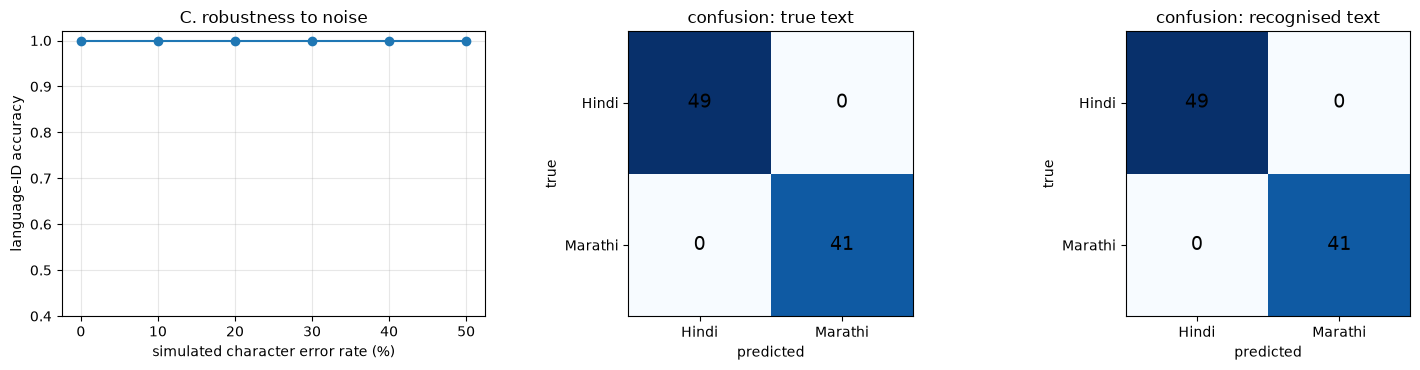

In [4]:
# C. how robust is the identifier to recognition errors?
rng = random.Random(0)
rates = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
accs = []
for rate in rates:
    noisy = [D.corrupt_text(t, rate, rng) for t in te.text]
    accs.append(accuracy_score(list(te.language), lid.predict(noisy)))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot([r * 100 for r in rates], accs, "o-"); ax[0].set_ylim(0.4, 1.02); ax[0].grid(alpha=.3)
ax[0].set_xlabel("simulated character error rate (%)"); ax[0].set_ylabel("language-ID accuracy"); ax[0].set_title("C. robustness to noise")
for a, key, title in [(ax[1], "test_true_text", "confusion: true text"), (ax[2], "test_recognised_text", "confusion: recognised text")]:
    cm = np.array(R[key]["cm"]); a.imshow(cm, cmap="Blues")
    a.set_xticks([0, 1]); a.set_xticklabels(LABELS); a.set_yticks([0, 1]); a.set_yticklabels(LABELS)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(title)
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", color="black", fontsize=14)
plt.tight_layout(); plt.savefig(cfg["out"] / "figures" / "language_id.png", dpi=150); plt.show()

## 3. The complete system: photo -> text + language

In [5]:
final = json.load(open(cfg["out"] / "results" / "final_decoder.json"))
lm = D.CharNgramLM(order=5).fit(list(data["train"].text)) if final["alpha"] > 0 else None
rec = T.Recognizer(final["tag"], data, cfg, lm=lm, beam=max(1, final["beam"]), alpha=final["alpha"],
                   beta=final["beta"], use_beam=(final["decoder"] != "greedy"))
print("recogniser:", final)

def recognize_and_identify(path):
    text, info, strip = rec(path)
    if not text.strip():
        return "", "unknown", 0.0
    proba, classes = lid.predict_proba([text])
    k = int(np.argmax(proba[0]))
    return text, classes[k], float(proba[0][k])

recogniser: {'tag': 'tcn', 'decoder': 'beam+LM', 'beam': 10, 'alpha': 0.3, 'beta': 1.0, 'test_CER': 0.19917901938426455, 'test_WER': 0.5005417118093174, 'greedy_test_CER': 0.23042189281641962}


hi_153_14652
  reference : लक्ष्मण ने मेघनाद से युद्ध करके उसका वध कर दिया। कौन झूठे धर्मों का नाश करेगा? हमने तुम्हें सात'मसानी'का समूह यानी महान क़ुरआन दिया- लेकिन क
  recognised: लक्षण ने मेहनाद से युद्ध कसे उसकातत कर दिया। कौन झरढे धमों का नाश करेगा? हमने तुम्हें सात. मामी का समूह यांनी महान करआन दिया लेकिन क्या परमे
  language  : Hindi (0.99)

hi_72_1941
  reference : कोई भी अनियमित बात नहीं की गई है। मैनें स्वयं अपने कानों से यह सब सुना। यह बात चात्रिक के अधिकतर गीतों पर लागू होती है। और हमने (आमादा देखकर
  recognised: कोई भी अनियमित वादा नहीं की गरई हैं। मैंने स्वय अपने कानों से यह सब्त सुना। यह व्यात चांत्रिक के अधिकतर गीतों पर ला्ू होती हैं। और हमने (आमा
  language  : Hindi (1.00)

ma_282_139760
  reference : अनेक वर्षांपासून त्यांचा तो दिनक्रम आहे. आत्तापर्यंत ७७७ विमानांच्या अपघातांत एकही प्रवासी मृत्यू पावलेला नाही. तर तुम्हाला अनेक रोबो लागतील
  recognised: अनेक वर्षांपायूने त्यांचा तो दिन क्रम आहे. आत्तापर्यंत ज विमानांच्या अपधातात एकही प्रकायी मृत्यू पावलेला नाही. तर तुम

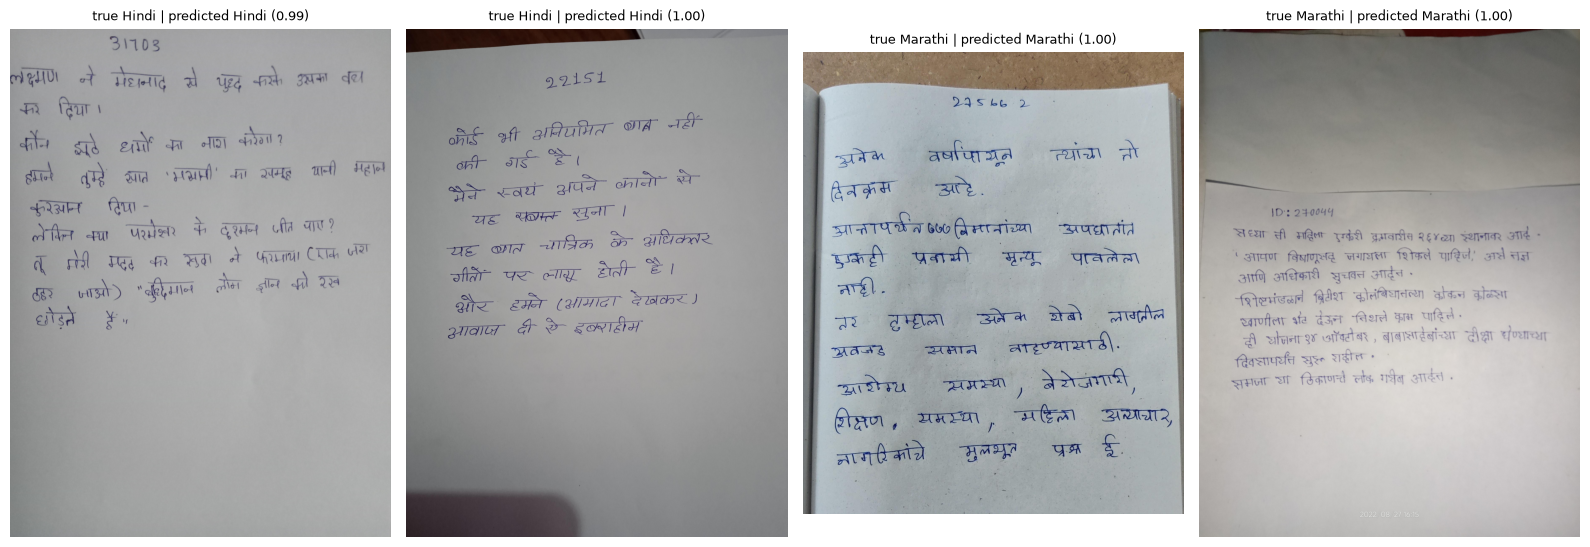

In [6]:
demo = te.groupby("language").sample(2, random_state=1)
fig, axes = plt.subplots(1, len(demo), figsize=(4 * len(demo), 6))
for ax, (_, r) in zip(np.atleast_1d(axes), demo.iterrows()):
    text, lang, conf = recognize_and_identify(r.image)
    img = cv2.imdecode(np.fromfile(r.image, dtype=np.uint8), cv2.IMREAD_COLOR)[:, :, ::-1]
    ax.imshow(img); ax.axis("off"); ax.set_title(f"true {r.language} | predicted {lang} ({conf:.2f})", fontsize=9)
    print(f"{r.id}\n  reference : {r.text[:140]}\n  recognised: {text[:140]}\n  language  : {lang} ({conf:.2f})\n")
plt.tight_layout(); plt.show()

## 4. Test on the unlabelled folders (language known from the folder name)

Each page takes a few seconds on CPU, so a sample is used. Raise `N_PER_LANG` for a larger test.

In [7]:
N_PER_LANG = 40
rows = []
for lang, info in D.find_language_folders(cfg["data_root"]).items():
    imgs = []
    for d in info["unlabelled"]:
        imgs += sorted(p for p in d.glob("*") if p.suffix.lower() in D.IMG_EXT)
    random.Random(0).shuffle(imgs)
    for p in imgs[:N_PER_LANG]:
        try:
            text, pred_lang, conf = recognize_and_identify(p)
        except Exception as e:
            text, pred_lang, conf = "", "error", 0.0
        rows.append(dict(image=p.name, true_language=lang, pred_language=pred_lang, confidence=conf, recognised=text))
e2e = pd.DataFrame(rows)
if len(e2e):
    e2e.to_csv(cfg["out"] / "results" / "unlabelled_test_predictions.csv", index=False, encoding="utf-8-sig")
    R["unlabelled_folders_end_to_end"] = report(list(e2e.true_language), list(e2e.pred_language), "D. unlabelled test folders, full pipeline")
    print("pages with no recognised text / errors:", int(e2e.pred_language.isin(["unknown", "error"]).sum()))
else:
    print("no unlabelled test folders found - skipped")


D. unlabelled test folders, full pipeline: accuracy 0.9750  (80 items)
         precision  recall      F1
Hindi       0.9756    1.00  0.9877
Marathi     1.0000    0.95  0.9744
pages with no recognised text / errors: 1


## 5. Final summary of the whole project

In [8]:
comp = pd.read_csv(cfg["out"] / "results" / "model_comparison.csv")
final = json.load(open(cfg["out"] / "results" / "final_decoder.json"))
print("RECOGNITION (test pages, writers not seen in training)")
print(comp.round(4).to_string(index=False))
print(f"\nbest model: {final['tag']} | decoder: {final['decoder']} (beam {final['beam']}, LM weight {final['alpha']}) "
      f"| test CER {final['test_CER']:.4f}  WER {final['test_WER']:.4f}")
print("\nLANGUAGE IDENTIFICATION")
for k, v in R.items():
    print(f"  {k:32s} accuracy {v['accuracy']:.4f}   F1 {np.round(v['f1'], 4).tolist()}")

json.dump(dict(recognition=comp.to_dict("records"), final_decoder=final, language_id=R),
          open(cfg["out"] / "results" / "final_summary.json", "w"), indent=2)
print("\nsaved results/final_summary.json. Single photo from the command line:  python predict.py path\\to\\photo.jpg")

RECOGNITION (test pages, writers not seen in training)
        tag  down  params  best_epoch  train_minutes  val_CER  val_WER  test_CER  test_WER
        cnn     4 1428860          58          427.3   0.3675   0.7427    0.2313    0.6295
        tcn     8 2746748          50          194.6   0.3595   0.7133    0.2304    0.6127
transformer     8 3142780          44          257.5   0.3953   0.7976    0.2686    0.6939

best model: tcn | decoder: beam+LM (beam 10, LM weight 0.3) | test CER 0.1992  WER 0.5005

LANGUAGE IDENTIFICATION
  val_true_text                    accuracy 1.0000   F1 [1.0, 1.0]
  test_true_text                   accuracy 1.0000   F1 [1.0, 1.0]
  test_recognised_text             accuracy 1.0000   F1 [1.0, 1.0]
  unlabelled_folders_end_to_end    accuracy 0.9750   F1 [0.9877, 0.9744]

saved results/final_summary.json. Single photo from the command line:  python predict.py path\to\photo.jpg
